In [80]:
#필요한 도구 가져오기
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler 
from sklearn.model_selection import train_test_split
from scipy.special import expit

In [81]:
# [ 도미 ]
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0,
33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0,
610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

# [ 빙어 ]
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [82]:
# 도미와 빙어 구분하는 머신러닝을 구성하시오
# - 길이21,무게90의 고기를 예측하시오.(logisticregression()알고리즘 사용)
# 도미,빙어 길이와 무게의 산점도 그래프를 출력하시오.
# 길이 25, 무게 150의 생선을 예측하시오.

In [83]:
len(bream_length)
len(smelt_length)

14

In [84]:
# 데이터 합치기
total_length = bream_length+ smelt_length
total_weight = bream_weight+ smelt_weight

In [85]:
# 데이터 전처리
data = np.column_stack((total_length,total_weight))                   # 49행 2열 배열(길이,무게)
label = ['bream']*len(bream_length) + ['smelt']*len(smelt_length)
#label = ['bream']*35 + ['smelt']*14

In [86]:
# 데이터 분리
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)

In [87]:
# 정규화 작업
ss= StandardScaler()
ss.fit(train_data)
train_scaled= ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [88]:
# 데이터 학습
lr = LogisticRegression()
lr.fit(train_scaled,train_label)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [89]:
new = [[21,90]]
new2 = [[25,150]]

In [90]:
# 예측
# in_data = input('생선의 길이,무게를 입력하세요>> 예)21,90')
in_data ='21,90'
in_data= in_data.split(',')
in_data2 =list(map(float,in_data))
in_data2

[21.0, 90.0]

In [91]:
#정규화
new_scaled = ss.transform([[21,90]])
new2_scaled = ss.transform([[25,150]])

In [92]:
#예측
result = lr.predict(new_scaled)          #예측종류
result2 = lr.predict(new2_scaled)          
result[0]
p_result = lr.predict_proba(new_scaled)     #두 생선 각각의 도미,빙어 확률
p_result2 = lr.predict_proba(new2_scaled)     
p_result[0][0]

print(f'예측생선 : {result[0]}, ({p_result[0][1]*100:.2f}%)')
print(f'예측생선 : {result2[0]}, ({p_result2[0][0]*100:.2f}%)')

예측생선 : smelt, (55.23%)
예측생선 : bream, (67.84%)


In [93]:
lr.predict_proba(test_scaled[:5])

array([[0.94088243, 0.05911757],
       [0.11387061, 0.88612939],
       [0.15599382, 0.84400618],
       [0.10985197, 0.89014803],
       [0.98807467, 0.01192533]])

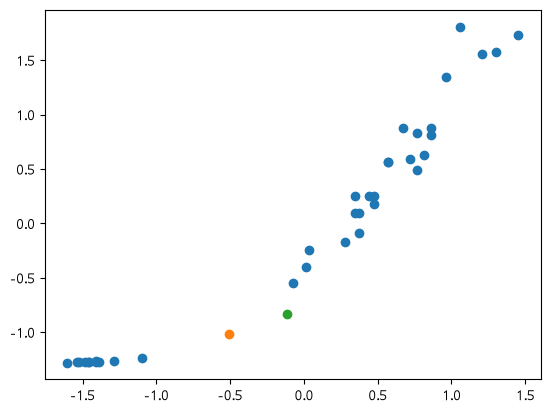

In [94]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_scaled[:,0],new_scaled[:,1])
plt.scatter(new2_scaled[:,0],new2_scaled[:,1])
plt.show()

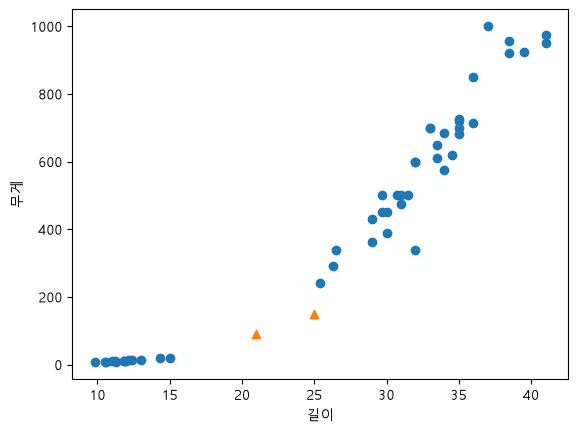

In [95]:
# 산점도그래프
plt.scatter(total_length,total_weight)
plt.scatter([21,25],[90,150],marker="^")

plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [ ]:
decisions = lr.decision_function(test_scaled[:5])
np.round(decisions,decimals=4)
expit(decisions)  #expit: 숫자를 0과1 사이의 값으로 바꾸는 함수

array([0.05911757, 0.88612939, 0.84400618, 0.89014803, 0.01192533])

In [97]:

#정확도
print('train_정확도:',lr.score(train_scaled,train_label))
print('test_정확도:',lr.score(test_scaled,test_label))

train_정확도: 1.0
test_정확도: 1.0
